#### Práctica 3: Tarea de clasificación

### Introducción
La deserción de estudiantes es uno de los principales problemas que enfrentan las universidades, ya que esto afecta tanto a los estudiantes como a las instituciones. Poder identificar de manera temprana a los alumnos que tienen mayor riesgo de abandonar sus estudios puede ayudar a implementar estrategias de apoyo  y mejorar las tasas de permanencia y graduación. Es bajo este contexto que se desarorlló el dataset *Predict Students' Dropout and Academic Success.*


Este dataset se hizo en base a datos reales de 4,424 estudiantes de licenciatura del Instituto Politécnico de Portalegre, Portugal, entre los ciclos escolares 2008/09 y 2018/19. El dataset disponible en el UCI Machine Learning Repository contiene información demográfica, socioeconómica y académica de los estudiantes. El objetivo principal es desarrollar un modelo de clasificación capaz de predecir la situación académica de un estudiante, utilizando únicamente la información disponible al cierre del primer semestre. Para ello, se consideran tres posibles clases:

**Graduate:** estudiantes que lograron graduarse.

**Dropout:** estudiantes que abandonaron sus estudios.

**Enrolled:** estudiantes que permanecen inscritos.

Se compararán cinco algoritmos de aprendizaje supervisado: **árboles de decisión, Naive Bayes, k vecinos más cercanos (kNN), máquinas de soporte vectorial (SVM) y regresión logística**. Cada modelo contará con un preprocesamiento y una optimización de hiperparámetros mediante validación cruzada estratificada.

Adicionalmente, se analizará cuánto podría mejorar el desempeño del mejor clasificador si se incorporara la información académica del segundo semestre. Esto permitirá discutir si resulta más conveniente realizar una predicción temprana o esperar a contar con información adicional.

Finalmente, se seleccionará el clasificador con mejor desempeño para entrenarlo con todos los datos disponibles del conjunto de entrenamiento y generar las predicciones correspondientes a los 885 estudiantes del conjunto de prueba.

### Análisis exploratorio de datos (EDA)
Para comenzar, se cargan los archivos de entrenamiento y prueba proporcionados para la práctica. El conjunto de entrenamiento contiene las características de los estudiantes y su situación académica final (Target), mientras que el conjunto de prueba no incluye esta variable, ya que será utilizada para evaluar las predicciones del modelo final.

También se revisan las dimensiones de ambos conjuntos y sus primeras observaciones para comprobar que los archivos se hayan cargado correctamente.
### Librerias

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
import time

In [5]:
RANDOM_STATE = 42

# Rutas relativas
DATA_DIR = Path("datos")

train = pd.read_csv("desercion-entrenamiento.csv")
test = pd.read_csv("desercion-prueba.csv")

# Dimensiones
print("Entrenamiento:", train.shape)
print("Prueba:", test.shape)

display(train.head())
display(test.head())

Entrenamiento: (3539, 38)
Prueba: (885, 31)


,id,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,1,1,2,9500,1,1,140.0,1,38,...,0,8,8,8,15.637500,0,13.9,-0.3,0.79,Graduate
1,2,1,17,1,8014,0,1,125.0,1,37,...,0,6,7,6,11.666667,0,10.8,1.4,1.74,Graduate
2,3,1,39,1,9991,0,1,130.0,1,1,...,0,5,12,1,12.000000,0,11.1,0.6,2.02,Dropout
3,4,1,42,1,8014,0,1,150.0,1,19,...,0,6,8,5,12.000000,0,9.4,-0.8,-3.12,Graduate
4,5,2,42,1,9254,1,1,136.0,1,2,...,2,6,12,2,12.500000,0,7.6,2.6,0.32,Dropout


,id,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,...,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Unemployment rate,Inflation rate,GDP
0,6,1,17,1,9085,1,1,113.0,1,19,...,0,0,6,6,6,14.500000,0,8.9,1.4,3.51
1,12,1,1,1,9003,1,1,140.0,1,38,...,0,0,6,7,6,16.000000,0,12.4,0.5,1.79
2,15,1,1,1,9085,1,1,132.0,1,1,...,0,0,6,10,6,13.428571,0,13.9,-0.3,0.79
3,18,1,39,1,9085,1,1,133.1,1,37,...,0,0,6,11,6,12.125000,0,12.4,0.5,1.79
4,19,1,44,1,9238,1,39,140.0,1,1,...,0,3,6,7,6,12.333333,0,13.9,-0.3,0.79


La diferencia de siete columnas corresponde a `Target` y los seis atributos académicos del segundo semestre, que no están disponibles en prueba.

Aunque el conjunto de entrenamiento contiene información de los dos primeros semestres, el modelo principal va utilizar únicamente los atributos disponibles al finalizar el primero. Esto se debe a que en una situación real, no sería posible conocer el desempeño académico del estudiante durante el segundo semestre de forma anticipada. Por lo tanto, se identificarán las variables comunes entre entrenamiento y prueba, excluyendo id, que funciona únicamente como identificador. Las variables del segundo semestre se usarán para un experimento posterior.

In [6]:
# Variables disponibles al cierre del primer semestre
features_1sem = [
    col for col in test.columns
    if col != "id"
]

# Variables adicionales del segundo semestre
features_2sem = [
    col for col in train.columns
    if "2nd sem" in col
]

print("Variables disponibles:", len(features_1sem))
print("Variables del segundo semestre:", len(features_2sem))

print("\nVariables del segundo semestre:")
for col in features_2sem:
    print("-", col)

# Datos que utilizaremos en la comparación principal
X = train[features_1sem].copy()
y = train["Target"].copy()

X_test = test[features_1sem].copy()

assert list(X.columns) == list(X_test.columns)
assert "Target" not in X.columns
assert "id" not in X.columns

Variables disponibles: 30
Variables del segundo semestre: 6

Variables del segundo semestre:
- Curricular units 2nd sem (credited)
- Curricular units 2nd sem (enrolled)
- Curricular units 2nd sem (evaluations)
- Curricular units 2nd sem (approved)
- Curricular units 2nd sem (grade)
- Curricular units 2nd sem (without evaluations)


Ahora analizaremos cuántos estudiantes pertenecen a cada clase, esto nos permitirá identificar si existe desbalance.

,Cantidad,Porcentaje (%)
Target,,
Graduate,1767,49.93
Dropout,1137,32.13
Enrolled,635,17.94


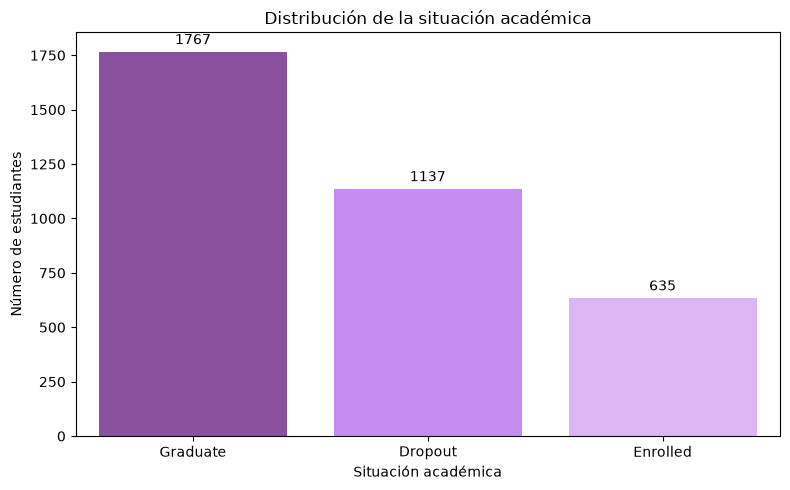

In [ ]:
# Distribución de clases
conteo = y.value_counts()
porcentaje = y.value_counts(normalize=True) * 100

distribucion = pd.DataFrame({
    "Cantidad": conteo,
    "Porcentaje (%)": porcentaje.round(2)
})

display(distribucion)

# Visualización
plt.figure(figsize=(8, 5))

colores = ["#8E44AD", "#FB7DFF", "#DCABF8"]

ax = sns.countplot(
    data=train,
    x="Target",
    order=["Graduate", "Dropout", "Enrolled"],
    hue="Target",
    palette=colores,
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Distribución de la situación académica")
plt.xlabel("Situación académica")
plt.ylabel("Número de estudiantes")
plt.tight_layout()
plt.show()

La distribución de la variable objetivo muestra que la clase más frecuente es **Graduate**, con 1,767 estudiantes (49.93 %), seguida de **Dropout**, con 1,137 (32.13 %), y finalmente **Enrolled**, con 635 (17.94 %). Se puede observar que existe un desbalance entre las clases aunque no es muy pronunciado. Sin embargo, un clasificador podría favorecer a los estudiantes graduados por ser la clase mayoritaria y obtener una exactitud relativamente alta sin identificar correctamente a los estudiantes de las otras categorías. 

Por esta razón, utilizaremos **F1 macro** como métrica principal, ya que calcula el F1 de cada clase y posteriormente obtiene su promedio sin dar mayor importancia a las clases más numerosas.

In [8]:
# Variables categóricas nominales
categoricas = [
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

# Variables numéricas o con orden cuantitativo
numericas = [
    col for col in features_1sem
    if col not in categoricas
]

print("Categóricas:", len(categoricas))
print("Numéricas:", len(numericas))

assert set(categoricas + numericas) == set(features_1sem)

resumen_atributos = pd.DataFrame({
    "Atributo": features_1sem,
    "Tipo": [
        "Categórica" if col in categoricas else "Numérica"
        for col in features_1sem
    ],
    "Valores únicos": [
        train[col].nunique() for col in features_1sem
    ]
})

display(resumen_atributos)

Categóricas: 17
Numéricas: 13


,Atributo,Tipo,Valores únicos
0,Marital status,Categórica,6
1,Application mode,Categórica,17
2,Application order,Numérica,8
3,Course,Categórica,17
4,Daytime/evening attendance,Categórica,2
5,Previous qualification,Categórica,17
6,Previous qualification (grade),Numérica,100
7,Nacionality,Categórica,18
8,Mother's qualification,Categórica,26
9,Father's qualification,Categórica,32


El dataset contiene tanto variables numéricas como categóricas. Algo importante es que varios atributos nominales están representados mediante códigos enteros, por lo que no deben interpretarse directamente como cantidades. Por ejemplo, los códigos de `Course` identifican diferentes programas académicos, pero un código mayor no significa que un programa sea superior a otro.

Esta distinción será importante durante el preprocesamiento, ya que algunos algoritmos, como kNN, SVM y regresión logística, necesitan una representación numérica adecuada de las categorías.

In [9]:
print("Valores faltantes en entrenamiento:",
      train.isna().sum().sum())

print("Valores faltantes en prueba:",
      test.isna().sum().sum())

print("Filas duplicadas en entrenamiento:",
      train.duplicated().sum())

print("Filas duplicadas en prueba:",
      test.duplicated().sum())

print("IDs duplicados en entrenamiento:",
      train["id"].duplicated().sum())

print("IDs duplicados en prueba:",
      test["id"].duplicated().sum())

print("IDs compartidos:",
      len(set(train["id"]) & set(test["id"])))

# Estadísticas descriptivas de variables numéricas
display(X[numericas].describe().T)

Valores faltantes en entrenamiento: 0
Valores faltantes en prueba: 0
Filas duplicadas en entrenamiento: 0
Filas duplicadas en prueba: 0
IDs duplicados en entrenamiento: 0
IDs duplicados en prueba: 0
IDs compartidos: 0


,count,mean,std,min,25%,50%,75%,max
Application order,3539.0,1.723933,1.316427,0.00,1.0,1.000000,2.000000,9.000
Previous qualification (grade),3539.0,132.606810,13.122246,95.00,125.0,133.100000,140.000000,190.000
Admission grade,3539.0,127.002684,14.486109,95.00,117.9,126.300000,134.900000,190.000
Age at enrollment,3539.0,23.262786,7.622295,17.00,19.0,20.000000,25.000000,62.000
Curricular units 1st sem (credited),3539.0,0.741170,2.416784,0.00,0.0,0.000000,0.000000,20.000
Curricular units 1st sem (enrolled),3539.0,6.290195,2.505786,0.00,5.0,6.000000,7.000000,26.000
Curricular units 1st sem (evaluations),3539.0,8.303476,4.199722,0.00,6.0,8.000000,10.000000,45.000
Curricular units 1st sem (approved),3539.0,4.717152,3.119980,0.00,3.0,5.000000,6.000000,26.000
Curricular units 1st sem (grade),3539.0,10.658535,4.833317,0.00,11.0,12.285714,13.397368,18.875
Curricular units 1st sem (without evaluations),3539.0,0.140718,0.686608,0.00,0.0,0.000000,0.000000,12.000


En los archivos revisados no se encontraron valores faltantes ni filas completamente duplicadas. Sin embargo, también conviene revisar los valores extremos y la coherencia de las variables. 

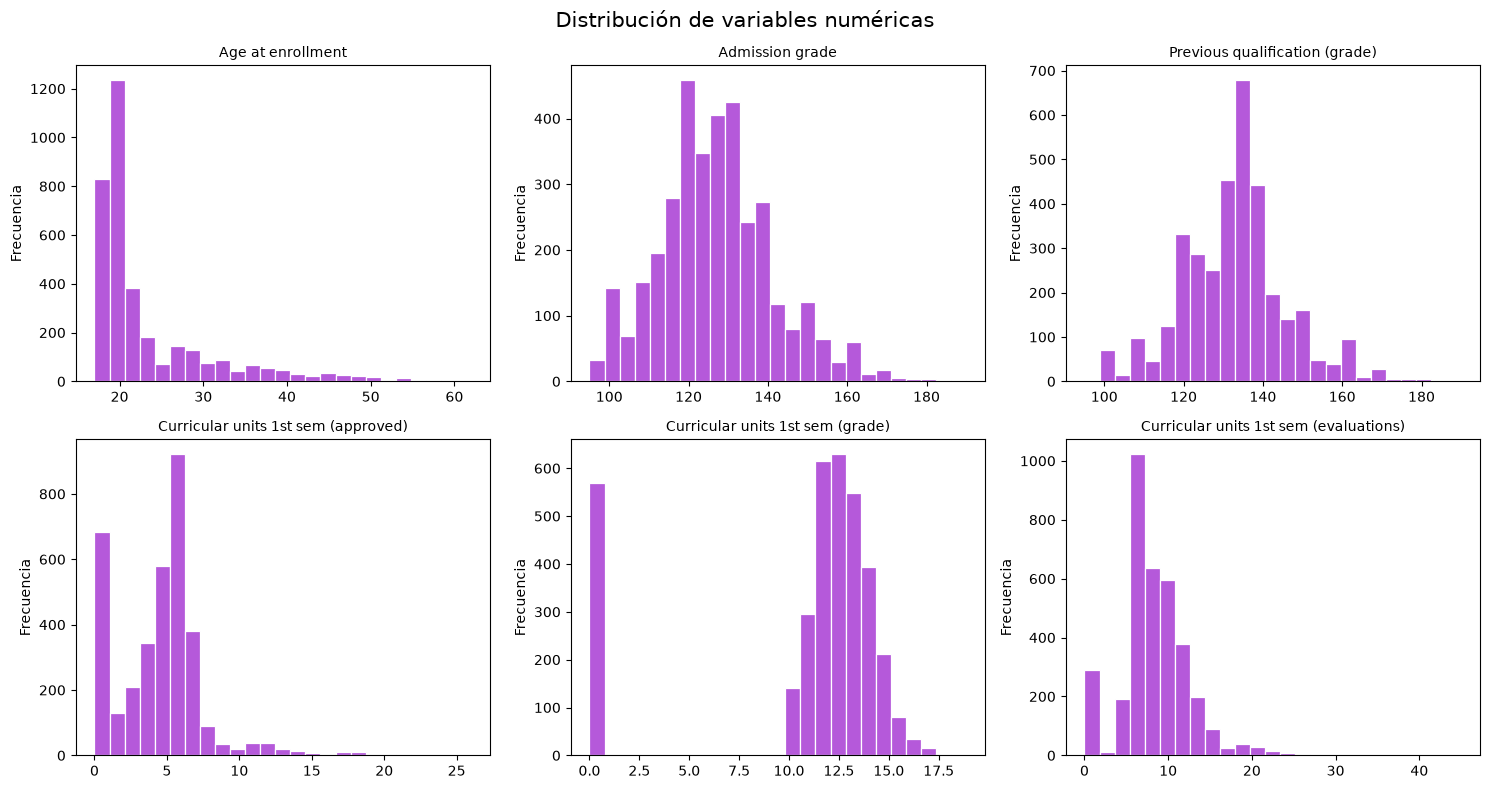

In [11]:
variables_eda = [
    "Age at enrollment",
    "Admission grade",
    "Previous qualification (grade)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (evaluations)"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, col in zip(axes, variables_eda):
    sns.histplot(
        data=train,
        x=col,
        bins=25,
        color="#9D21CE",
        edgecolor="white",
        ax=ax
    )
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Frecuencia")

plt.suptitle("Distribución de variables numéricas", fontsize=15)
plt.tight_layout()
plt.show()

Las gráficas muestran que las variables numéricas presentan distribuciones bastante diferentes. La mayoría de los estudiantes ingresaron a la universidad entre los 17 y 22 años, aunque existe una distribución asimétrica hacia la derecha debido a estudiantes mayores. Por otro lado, las calificaciones de admisión y de estudios previos se concentran principalmente entre 110 y 140, con distribuciones similares.

En cuanto al desempeño académico del primer semestre, la mayoría de los estudiantes aprobaron entre 4 y 6 unidades curriculares y realizaron aproximadamente entre 6 y 12 evaluaciones. Sin embargo, destaca una cantidad considerable de estudiantes con **cero unidades aprobadas**. De manera similar, las calificaciones del primer semestre se concentran entre 11 y 14, pero también presentan una acumulación importante en cero.

En general, estas distribuciones muestran que algunas variables presentan asimetrías, valores extremos y concentraciones particulares, especialmente las relacionadas con el desempeño académico. Estas características deberán considerarse durante el preprocesamiento, ya que pueden influir de manera diferente en el comportamiento de los clasificadores.

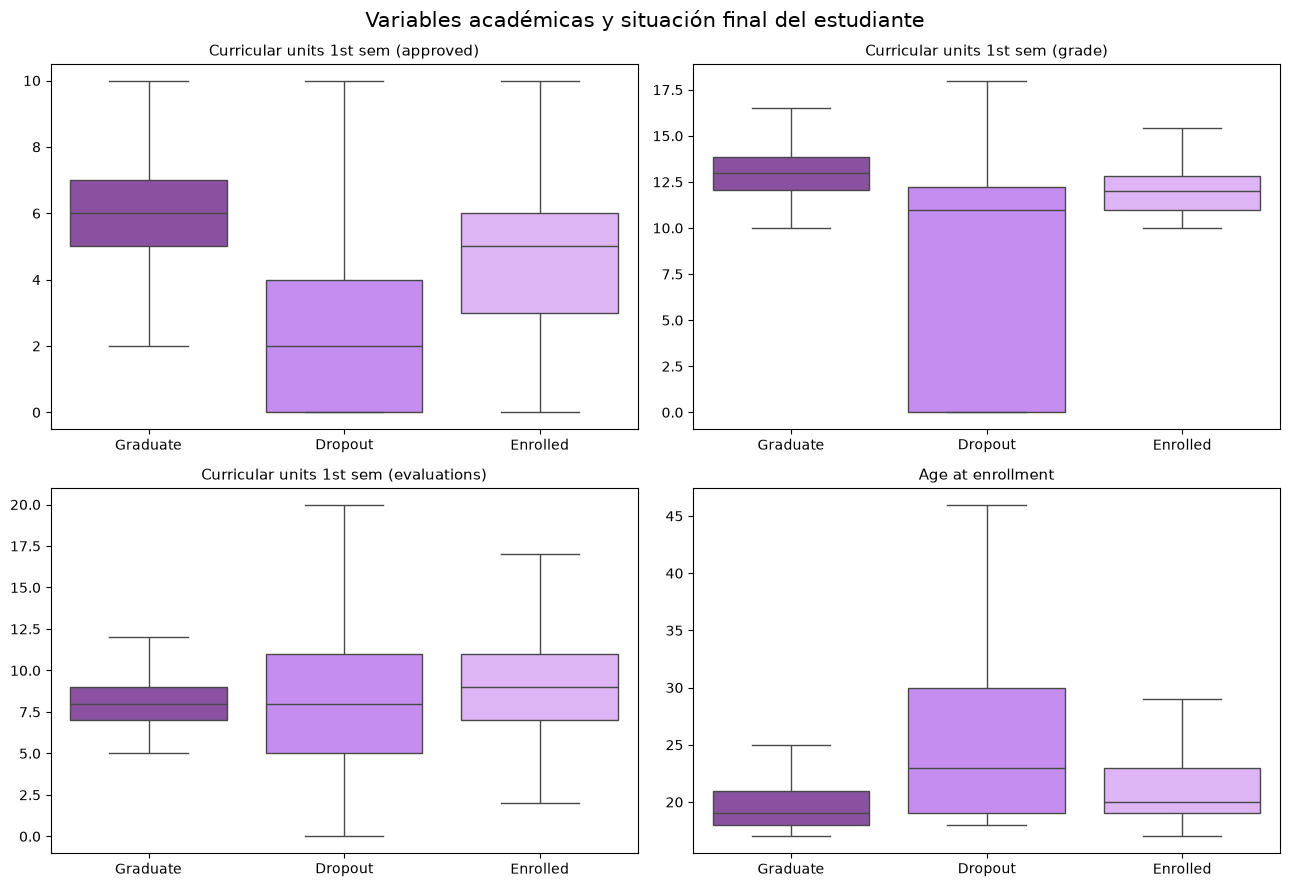

In [12]:
variables_academicas = [
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (evaluations)",
    "Age at enrollment"
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, col in zip(axes.flatten(), variables_academicas):
    sns.boxplot(
        data=train,
        x="Target",
        y=col,
        order=["Graduate", "Dropout", "Enrolled"],
        hue="Target",
        palette=["#8E44AD", "#C77DFF", "#E0AAFF"],
        legend=False,
        showfliers=False,
        ax=ax
    )

    ax.set_title(col, fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.suptitle(
    "Variables académicas y situación final del estudiante",
    fontsize=15
)
plt.tight_layout()
plt.show()

Los diagramas muestran que el desempeño académico durante el primer semestre está relacionado con la situación final de los estudiantes. Los alumnos que lograron graduarse presentan una mediana de **6 unidades curriculares aprobadas**, mientras que los que abandonaron sus estudios tienen una mediana de apenas **2 unidades**. De manera similar, las calificaciones de los estudiantes graduados son generalmente más altas y presentan menor dispersión, mientras que los desertores muestran una mayor variabilidad y una cantidad considerable de calificaciones iguales a cero.

Las tres clases presentan medianas relativamente similares en número de evaluaciones, aunque los estudiantes que abandonaron sus estudios muestran una mayor dispersión. Por otro lado, los desertores tienden a ingresar a la universidad a una edad más avanzada, con una mediana cercana a los 23 años, frente a aproximadamente 19 y 20 años en las otras clases.

En general, los resultados sugieren que **las unidades aprobadas y las calificaciones del primer semestre podrían ser variables importantes para predecir la deserción estudiantil**. Sin embargo, existe superposición entre las clases, por lo que será necesario combinar diferentes atributos para mejorar las predicciones.

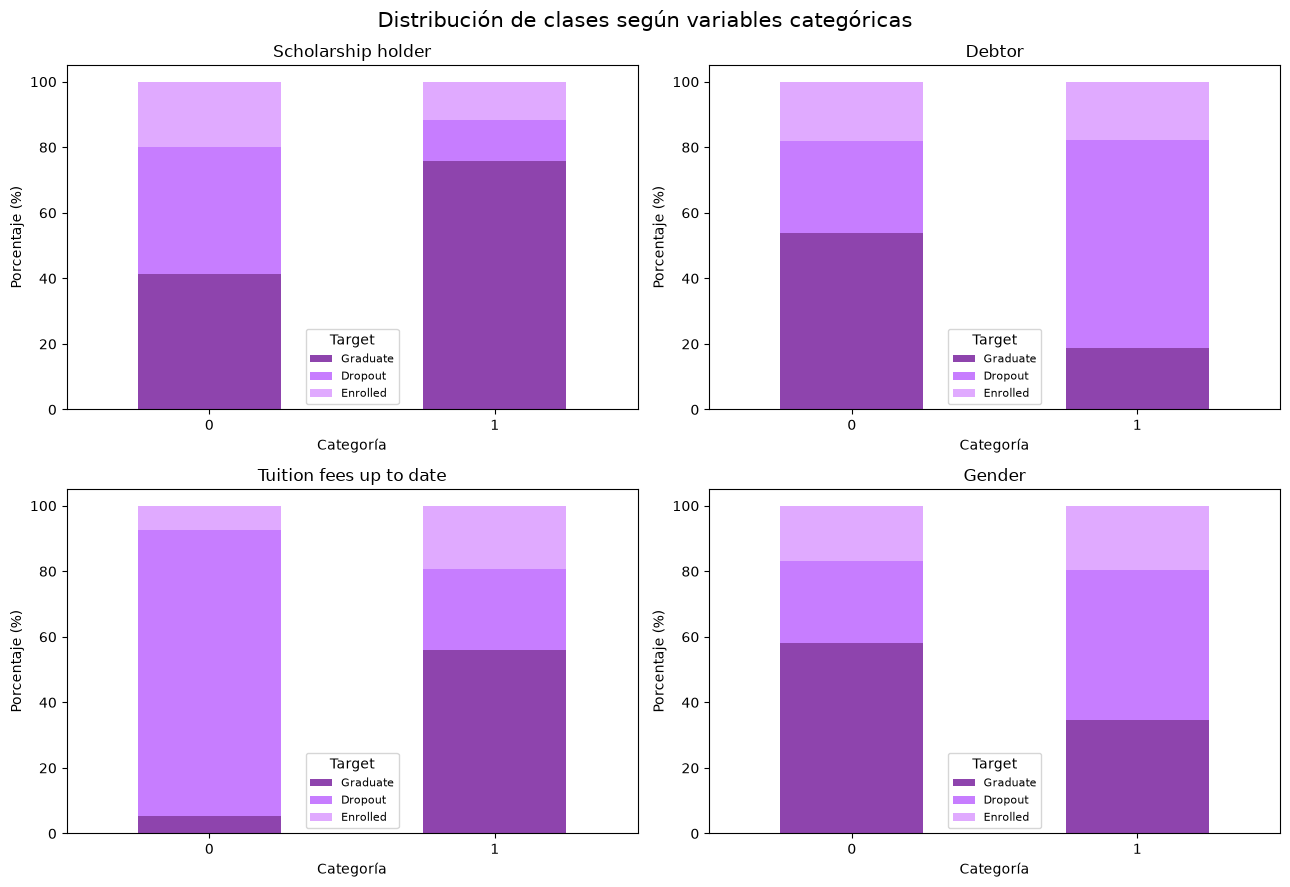

In [13]:
variables_cat_eda = [
    "Scholarship holder",
    "Debtor",
    "Tuition fees up to date",
    "Gender"
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, col in zip(axes.flatten(), variables_cat_eda):

    tabla = pd.crosstab(
        train[col],
        train["Target"],
        normalize="index"
    ) * 100

    tabla = tabla.reindex(
        columns=["Graduate", "Dropout", "Enrolled"]
    )

    tabla.plot(
        kind="bar",
        stacked=True,
        color=["#8E44AD", "#C77DFF", "#E0AAFF"],
        ax=ax
    )

    ax.set_title(col)
    ax.set_xlabel("Categoría")
    ax.set_ylabel("Porcentaje (%)")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="Target", fontsize=8)

plt.suptitle(
    "Distribución de clases según variables categóricas",
    fontsize=15
)
plt.tight_layout()
plt.show()

Las gráficas muestran que algunas variables categóricas presentan una relación considerable con la situación académica final de los estudiantes. En particular, quienes cuentan con una beca (*Scholarship holder = 1*) tienen una proporción considerablemente mayor de graduados, cercana al 76 %, mientras que entre quienes no tienen beca esta proporción es aproximadamente del 41% Por otro lado, los estudiantes que presentan deudas (*Debtor = 1*) muestran una mayor proporción de deserción, cercana al 63 %. Esta tendencia es todavía más evidente entre quienes no están al corriente con sus pagos (*Tuition fees up to date = 0*), donde aproximadamente el 88 % corresponde a estudiantes que abandonaron sus estudios.

Finalmente, también se observan diferencias según el género: los estudiantes codificados con `Gender = 0`(mujeres) presentan una mayor proporción de graduados que aquellos con `Gender = 1`(hombres).

En general, estos resultados sugieren que **las condiciones económicas y administrativas podrían ser variables relevantes para predecir la deserción estudiantil**. Sin embargo, las relaciones observadas no implican necesariamente causalidad y deberán evaluarse junto con los demás atributos mediante los modelos de clasificación.

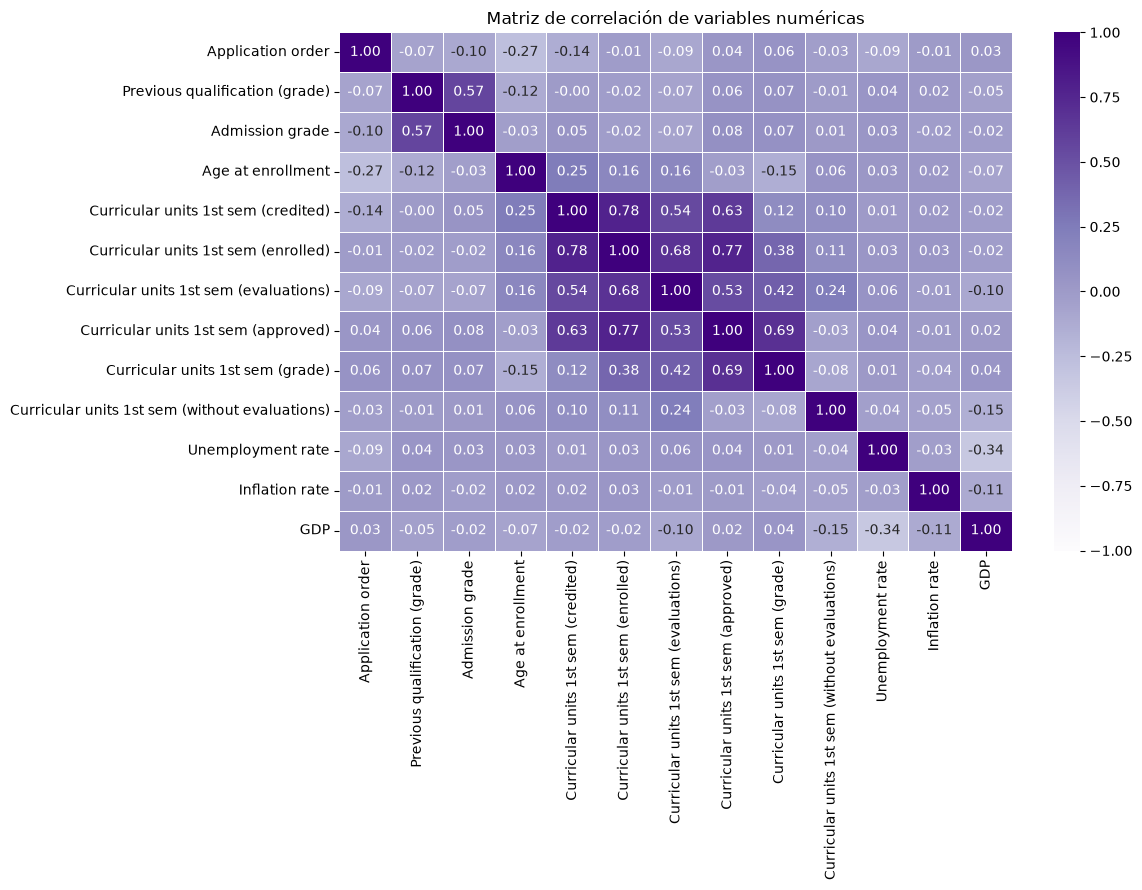

In [14]:
corr = X[numericas].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="Purples",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.show()

La matriz de correlación muestra que las relaciones más fuertes se encuentran entre las variables académicas del primer semestre, destacando las correlaciones entre las unidades curriculares acreditadas y matriculadas (r = 0.78), las unidades matriculadas y aprobadas (r = 0.77), y las unidades aprobadas y la calificación promedio (r = 0.69). Esto tiene sentido, ya que todas estas variables describen diferentes aspectos del desempeño académico del estudiante. 
En general, no se identificaron correlaciones superiores al umbral de |r| ≥ 0.80, por lo que no parece necesario eliminar variables únicamente por presentar una correlación lineal elevada. 

El EDA permitió conocer la estructura del dataset e identificar algunas características importantes para el desarrollo de los clasificadores. Primero, se encontró un desbalance moderado entre las tres clases, esto justifica utilizar F1 macro como métrica principal para comparar los modelos.

También se identificó que el conjunto contiene variables numéricas y categóricas codificadas mediante enteros, por lo que será necesario aplicar diferentes estrategias de preprocesamiento según cada algoritmo. Por otra parte, el desempeño académico durante el primer semestre parece tener una relación importante con la situación final del estudiante. 

Aunque los archivos no presentan valores faltantes, será necesario considerar las diferencias de escala, las posibles correlaciones entre atributos y el tratamiento adecuado de las variables categóricas. Estos resultados servirán como punto de partida para construir y optimizar los cinco clasificadores, utilizando únicamente la información disponible al cierre del primer semestre.

### Árbol de decisión 
Los árboles de decisión son algoritmos de aprendizaje supervisado que clasifican observaciones mediante reglas construidas a partir de los atributos. En cada nodo, el algoritmo selecciona una condición que permite dividir los datos en grupos cada vez más homogéneos. Una ventaja de este método es que no requiere estandarizar las variables numéricas, ya que sus decisiones se basan en comparaciones con determinados umbrales. Sin embargo, es importante tratar adecuadamente los atributos categóricos, porque varios están representados mediante códigos enteros que no necesariamente tienen un significado ordinal. Por esta razón, utilizaremos One-Hot Encoding para las variables nominales y conservaremos las numéricas en su escala original. Además, incorporaremos el preprocesamiento dentro de un Pipeline para evitar fugas de información durante la validación cruzada.

In [19]:
# Variables definidas durante el EDA:
# X, y, categoricas, numericas

preprocesamiento_arbol = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            Pipeline([
                ("imputador", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categoricas
        ),
        (
            "numericas",
            SimpleImputer(strategy="median"),
            numericas
        )
    ]
)

pipeline_arbol = Pipeline([
    ("preprocesamiento", preprocesamiento_arbol),
    ("modelo", DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ))
])

pipeline_arbol

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categoricas', ...), ('numericas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float

In [22]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Mismas particiones para todos los modelos
cv_splits = list(cv.split(X, y))

print("Número de folds:", len(cv_splits))

for i, (idx_train, idx_val) in enumerate(cv_splits, start=1):
    print(
        f"Fold {i}: "
        f"{len(idx_train)} entrenamiento, "
        f"{len(idx_val)} validación"
    )

Número de folds: 5
Fold 1: 2831 entrenamiento, 708 validación
Fold 2: 2831 entrenamiento, 708 validación
Fold 3: 2831 entrenamiento, 708 validación
Fold 4: 2831 entrenamiento, 708 validación
Fold 5: 2832 entrenamiento, 707 validación


Utilizaremos cinco particiones estratificadas. De esta manera, cada fold conservará aproximadamente la proporción original de las tres clases. Además, guardaremos estas particiones para reutilizarlas con los otros cuatro algoritmos, de modo que las comparaciones sean justas. 

Uno de los principales problemas de los árboles de decisión es el sobreajuste, ya que si se permite que el árbol crezca sin restricciones, puede aprender reglas demasiado específicas y perder capacidad de generalización. Para controlar este comportamiento, se evaluarán diferentes valores de profundidad máxima, tamaño mínimo de las hojas y poda, además de comparar los criterios Gini y entropía. También se analizará el efecto de utilizar pesos balanceados para las clases.

La búsqueda se realizará mediante RandomizedSearchCV, evaluando 80 configuraciones con validación cruzada estratificada de cinco folds. La métrica de selección será F1 macro, con el objetivo de encontrar un modelo que mantenga un buen desempeño en las tres clases.

In [26]:
parametros_arbol = {
    "modelo__criterion": ["gini", "entropy"],
    "modelo__max_depth": [None, 3, 5, 7, 10, 15, 20, 30],
    "modelo__min_samples_split": randint(2, 31),
    "modelo__min_samples_leaf": randint(1, 16),
    "modelo__ccp_alpha": [
        0.0, 0.0001, 0.0005, 0.001,
        0.002, 0.005, 0.01, 0.02
    ],
    "modelo__class_weight": [None, "balanced"]
}

busqueda_arbol = RandomizedSearchCV(
    estimator=pipeline_arbol,
    param_distributions=parametros_arbol,
    n_iter=80,
    scoring="f1_macro",
    cv=cv_splits,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    refit=True,
    return_train_score=True,
    error_score="raise"
)

inicio = time.perf_counter()

busqueda_arbol.fit(X, y)

tiempo_arbol = time.perf_counter() - inicio

print("Mejor F1 macro:", round(busqueda_arbol.best_score_, 4))
print("Tiempo de búsqueda:", round(tiempo_arbol, 2), "segundos")
print("Configuraciones evaluadas:", len(busqueda_arbol.cv_results_["params"]))

print("\nMejores hiperparámetros:")
for parametro, valor in busqueda_arbol.best_params_.items():
    print(f"{parametro}: {valor}")

Mejor F1 macro: 0.6402
Tiempo de búsqueda: 8.47 segundos
Configuraciones evaluadas: 80

Mejores hiperparámetros:
modelo__ccp_alpha: 0.0
modelo__class_weight: balanced
modelo__criterion: entropy
modelo__max_depth: 7
modelo__min_samples_leaf: 6
modelo__min_samples_split: 24


Primero revisaremos las mejores configuraciones, así como el promedio y la desviación estándar del F1 macro obtenidos durante la validación cruzada.

In [28]:
resultados_arbol = pd.DataFrame(busqueda_arbol.cv_results_)

columnas_resultados = [
    "rank_test_score",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "param_modelo__max_depth",
    "param_modelo__min_samples_leaf",
    "param_modelo__ccp_alpha",
    "param_modelo__class_weight"
]

display(
    resultados_arbol[columnas_resultados]
    .sort_values("rank_test_score")
    .head(10)
)

mejor_indice = busqueda_arbol.best_index_

f1_arbol = busqueda_arbol.best_score_
std_arbol = resultados_arbol.loc[mejor_indice, "std_test_score"]

print(f"F1 macro promedio: {f1_arbol:.4f}")
print(f"Desviación estándar: {std_arbol:.4f}")

,rank_test_score,mean_train_score,mean_test_score,std_test_score,param_modelo__max_depth,param_modelo__min_samples_leaf,param_modelo__ccp_alpha,param_modelo__class_weight
47,1,0.688593,0.640208,0.016030,7,6,0.000,balanced
37,2,0.685007,0.638600,0.009947,7,12,0.002,balanced
14,3,0.702637,0.637533,0.014198,7,2,0.001,balanced
48,4,0.680567,0.636559,0.010226,None,3,0.002,balanced
54,5,0.707341,0.636284,0.014195,7,3,0.001,balanced
12,6,0.708038,0.634059,0.013805,7,7,0.001,balanced
50,7,0.708314,0.632313,0.007296,30,11,0.001,None
30,8,0.637975,0.632111,0.007141,20,11,0.010,None
22,8,0.637975,0.632111,0.007141,None,12,0.010,None
15,10,0.660039,0.631879,0.009042,15,13,0.005,balanced


F1 macro promedio: 0.6402
Desviación estándar: 0.0160
